In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import re

In [33]:
# 1. Primary Base Meteorology Grid (Contains Multiple Variables)
gdf_meteo_winds = gpd.read_file('Accra_meteo_clean.geojson')

In [7]:
gdf_meteo_raw.head()

,id,date,latitude,longitude,u10,v10,wind_speed,wind_dir_deg,geometry
0,295,2026-01-01,5.5164,-0.2740,2.895965,2.239334,3.660770,232.286650,POINT (-0.274 5.5164)
1,483,2026-01-01,5.5170,-0.2706,2.895965,2.239334,3.660770,232.286650,POINT (-0.2706 5.517)
2,303,2026-01-01,5.5198,-0.2625,2.915393,2.265934,3.692421,232.144543,POINT (-0.2625 5.5198)
3,125,2026-01-01,5.5202,-0.2657,2.915393,2.265934,3.692421,232.144543,POINT (-0.2657 5.5202)
4,319,2026-01-01,5.5206,-0.2571,2.934821,2.292533,3.724095,232.004853,POINT (-0.2571 5.5206)


In [10]:
# 2. AOD Target Dataset
gdf_aod_raw = gpd.read_file('Accra_aod_Clean.geojson')

In [11]:
gdf_aod_raw.head()

,date_str,latitude,longitude,AOD_Raw,month,geometry
0,2026-01-01,5.516450,-0.274025,NaN,1,POINT (-0.27403 5.51645)
1,2026-01-01,5.517026,-0.270589,NaN,1,POINT (-0.27059 5.51703)
2,2026-01-01,5.519802,-0.262486,NaN,1,POINT (-0.26249 5.5198)
3,2026-01-01,5.520193,-0.265745,NaN,1,POINT (-0.26574 5.52019)
4,2026-01-01,5.520564,-0.257110,NaN,1,POINT (-0.25711 5.52056)


In [42]:

gdf_ele = gpd.read_file('Accra_elevation_Clean.geojson')

In [43]:
gdf_ele.head()

,id,aspect,elevation,slope,geometry
0,0,166.0,47.0,1.0,POINT (-0.15495 5.62302)
1,1,283.0,33.0,0.0,POINT (-0.25695 5.57202)
2,2,161.0,40.0,0.0,POINT (-0.17995 5.62352)
3,3,101.0,91.0,1.0,POINT (-0.18347 5.64817)
4,4,102.0,34.0,0.0,POINT (-0.24058 5.5517)


In [19]:
gdf_ph = gpd.read_file('Accra_PBLH_Hourly_2026_Clean.geojson')

In [20]:
gdf_ph.head()

,id,datetime,date,hour,latitude,longitude,PBLH,geometry
0,0,2026-01-01 00:00:00,2026-01-01,0,5.623,-0.1549,465.677460,POINT (-0.15495 5.62302)
1,0,2026-01-01 01:00:00,2026-01-01,1,5.623,-0.1549,470.263214,POINT (-0.15495 5.62302)
2,0,2026-01-01 02:00:00,2026-01-01,2,5.623,-0.1549,461.894928,POINT (-0.15495 5.62302)
3,0,2026-01-01 03:00:00,2026-01-01,3,5.623,-0.1549,451.084534,POINT (-0.15495 5.62302)
4,0,2026-01-01 04:00:00,2026-01-01,4,5.623,-0.1549,446.349823,POINT (-0.15495 5.62302)


In [21]:
gdf_pop = gpd.read_file('Accra_pop.geojson')

In [22]:
gdf_pop.head()

,id,mean,geometry
0,0,30.431883,POINT (-0.15495 5.62302)
1,1,138.209656,POINT (-0.25695 5.57202)
2,2,163.533142,POINT (-0.17995 5.62352)
3,3,110.263191,POINT (-0.18347 5.64817)
4,4,200.677017,POINT (-0.24058 5.5517)


In [30]:
gdf_pop = gdf_pop.rename(columns={'mean': 'pop_density'})

In [31]:
gdf_pop.head()

,id,pop_density,geometry
0,0,30.431883,POINT (-0.15495 5.62302)
1,1,138.209656,POINT (-0.25695 5.57202)
2,2,163.533142,POINT (-0.17995 5.62352)
3,3,110.263191,POINT (-0.18347 5.64817)
4,4,200.677017,POINT (-0.24058 5.5517)


In [23]:
gdf_no2 = gpd.read_file('Accra_no2_2026_Clean.geojson')

In [24]:
gdf_no2.head()

,id,date,latitude,longitude,NO2_column_density,geometry
0,295,2026-01-01,5.5164,-0.2740,NaN,POINT (-0.274 5.5164)
1,483,2026-01-01,5.5170,-0.2706,NaN,POINT (-0.2706 5.517)
2,303,2026-01-01,5.5198,-0.2625,NaN,POINT (-0.2625 5.5198)
3,125,2026-01-01,5.5202,-0.2657,NaN,POINT (-0.2657 5.5202)
4,319,2026-01-01,5.5206,-0.2571,NaN,POINT (-0.2571 5.5206)


In [25]:
gdf_no2 = gpd.read_file('Accra_no2_2026_Clean.geojson')

In [26]:
gdf_no2.head()

,id,date,latitude,longitude,NO2_column_density,geometry
0,295,2026-01-01,5.5164,-0.2740,NaN,POINT (-0.274 5.5164)
1,483,2026-01-01,5.5170,-0.2706,NaN,POINT (-0.2706 5.517)
2,303,2026-01-01,5.5198,-0.2625,NaN,POINT (-0.2625 5.5198)
3,125,2026-01-01,5.5202,-0.2657,NaN,POINT (-0.2657 5.5202)
4,319,2026-01-01,5.5206,-0.2571,NaN,POINT (-0.2571 5.5206)


In [28]:
gdf_ndvi = gpd.read_file('Accra_ndvi_Clean.geojson')

In [29]:
gdf_ndvi.head()

,id,date,latitude,longitude,NDVI,geometry
0,0,2026-01-01,5.623,-0.1549,0.3465,POINT (-0.1549 5.623)
1,0,2026-01-02,5.623,-0.1549,0.3465,POINT (-0.1549 5.623)
2,0,2026-01-03,5.623,-0.1549,0.3465,POINT (-0.1549 5.623)
3,0,2026-01-04,5.623,-0.1549,0.3465,POINT (-0.1549 5.623)
4,0,2026-01-05,5.623,-0.1549,0.3465,POINT (-0.1549 5.623)


In [34]:
df_meteo = gdf_meteo_winds.copy()
df_meteo['latitude'] = df_meteo.geometry.y.round(4)
df_meteo['longitude'] = df_meteo.geometry.x.round(4)
df_meteo['date'] = pd.to_datetime(df_meteo['date']).dt.strftime('%Y-%m-%d')

# Keep only necessary features
meteo_cols = ['date', 'latitude', 'longitude', 'u10', 'v10', 'wind_speed', 'wind_dir_deg']
# Include temp / relative_humidity if present in your meteo dataframe:
for extra_col in ['temp', 'relative_humidity', 'rh']:
    if extra_col in df_meteo.columns:
        meteo_cols.append(extra_col)

df_meteo_clean = df_meteo[meteo_cols].drop_duplicates(subset=['date', 'latitude', 'longitude'])

In [35]:
df_aod = gdf_aod_raw.copy()
# Rename date_str -> date and AOD_Raw -> AOD
df_aod = df_aod.rename(columns={'date_str': 'date', 'AOD_Raw': 'AOD'})
df_aod['latitude'] = df_aod.geometry.y.round(4)
df_aod['longitude'] = df_aod.geometry.x.round(4)
df_aod['date'] = pd.to_datetime(df_aod['date']).dt.strftime('%Y-%m-%d')

df_aod_clean = df_aod[['date', 'latitude', 'longitude', 'AOD']].drop_duplicates(subset=['date', 'latitude', 'longitude'])

In [36]:
df_no2 = gdf_no2.copy()
df_no2 = df_no2.rename(columns={'NO2_column_density': 'NO2'})
df_no2['latitude'] = df_no2.geometry.y.round(4)
df_no2['longitude'] = df_no2.geometry.x.round(4)
df_no2['date'] = pd.to_datetime(df_no2['date']).dt.strftime('%Y-%m-%d')

df_no2_clean = df_no2[['date', 'latitude', 'longitude', 'NO2']].drop_duplicates(subset=['date', 'latitude', 'longitude'])

In [37]:
df_ndvi = gdf_ndvi.copy()
df_ndvi['latitude'] = df_ndvi.geometry.y.round(4)
df_ndvi['longitude'] = df_ndvi.geometry.x.round(4)
df_ndvi['date'] = pd.to_datetime(df_ndvi['date']).dt.strftime('%Y-%m-%d')

df_ndvi_clean = df_ndvi[['date', 'latitude', 'longitude', 'NDVI']].drop_duplicates(subset=['date', 'latitude', 'longitude'])

In [38]:
df_pblh = gdf_ph.copy()
df_pblh['latitude'] = df_pblh.geometry.y.round(4)
df_pblh['longitude'] = df_pblh.geometry.x.round(4)
df_pblh['date'] = pd.to_datetime(df_pblh['date']).dt.strftime('%Y-%m-%d')

# Group hourly observations to daily aggregates
df_pblh_clean = df_pblh.groupby(['date', 'latitude', 'longitude']).agg(
    PBLH_mean=('PBLH', 'mean'),
    PBLH_min=('PBLH', 'min'),
    PBLH_max=('PBLH', 'max')
).reset_index()

In [40]:
gdf_ele.head()

,id,datetime,date,hour,latitude,longitude,PBLH,geometry
0,0,2026-01-01 00:00:00,2026-01-01,0,5.623,-0.1549,465.677460,POINT (-0.15495 5.62302)
1,0,2026-01-01 01:00:00,2026-01-01,1,5.623,-0.1549,470.263214,POINT (-0.15495 5.62302)
2,0,2026-01-01 02:00:00,2026-01-01,2,5.623,-0.1549,461.894928,POINT (-0.15495 5.62302)
3,0,2026-01-01 03:00:00,2026-01-01,3,5.623,-0.1549,451.084534,POINT (-0.15495 5.62302)
4,0,2026-01-01 04:00:00,2026-01-01,4,5.623,-0.1549,446.349823,POINT (-0.15495 5.62302)


In [44]:
# SRTM Terrain
df_srtm = gdf_ele.copy()
df_srtm['latitude'] = df_srtm.geometry.y.round(4)
df_srtm['longitude'] = df_srtm.geometry.x.round(4)
df_srtm_clean = df_srtm[['latitude', 'longitude', 'aspect', 'elevation', 'slope']].drop_duplicates(subset=['latitude', 'longitude'])

# WorldPop Population Density
df_pop = gdf_pop.copy()
df_pop['latitude'] = df_pop.geometry.y.round(4)
df_pop['longitude'] = df_pop.geometry.x.round(4)
df_pop_clean = df_pop[['latitude', 'longitude', 'pop_density']].drop_duplicates(subset=['latitude', 'longitude'])

In [45]:
# 1. Primary Backbone Grid (Meteorology + AOD)
master_df = pd.merge(
    df_meteo_clean, 
    df_aod_clean, 
    on=['date', 'latitude', 'longitude'], 
    how='left'
)

# 2. Join Dynamic Satellite Layers (NO2, NDVI, PBLH)
master_df = pd.merge(master_df, df_no2_clean,  on=['date', 'latitude', 'longitude'], how='left')
master_df = pd.merge(master_df, df_ndvi_clean, on=['date', 'latitude', 'longitude'], how='left')
master_df = pd.merge(master_df, df_pblh_clean, on=['date', 'latitude', 'longitude'], how='left')

# 3. Join Static Layers (SRTM Terrain & WorldPop Population)
master_df = pd.merge(master_df, df_srtm_clean, on=['latitude', 'longitude'], how='left')
master_df = pd.merge(master_df, df_pop_clean,  on=['latitude', 'longitude'], how='left')

In [46]:
# Check if any static terrain features are still missing
if master_df['elevation'].isnull().sum() > 0:
    print("📍 Running nearest-neighbor fallback for static terrain layers...")
    
    # Convert master back to GeoDataFrame
    master_gdf = gpd.GeoDataFrame(
        master_df, 
        geometry=gpd.points_from_xy(master_df['longitude'], master_df['latitude']),
        crs="EPSG:4326"
    ).to_crs("EPSG:32630") # Project to UTM Zone 30N (meters) for Ghana

    srtm_projected = gdf_srtm.to_crs("EPSG:32630")
    
    # Perform nearest spatial join
    sjoined_srtm = gpd.sjoin_nearest(
        master_gdf[['geometry']], 
        srtm_projected[['geometry', 'aspect', 'elevation', 'slope']], 
        how='left', 
        max_distance=1500
    )
    
    # Fill missing values
    master_df['elevation'] = master_df['elevation'].fillna(sjoined_srtm['elevation'])
    master_df['slope']     = master_df['slope'].fillna(sjoined_srtm['slope'])
    master_df['aspect']    = master_df['aspect'].fillna(sjoined_srtm['aspect'])

In [47]:
# Create Point Geometries for final export
master_gdf_final = gpd.GeoDataFrame(
    master_df,
    geometry=gpd.points_from_xy(master_df['longitude'], master_df['latitude']),
    crs="EPSG:4326"
)

# Sort by location and time
master_gdf_final = master_gdf_final.sort_values(['latitude', 'longitude', 'date']).reset_index(drop=True)

# Export to GeoJSON and CSV
#master_gdf_final.to_file("Accra_Master_Spatiotemporal_Panel.geojson", driver="GeoJSON")
#master_gdf_final.drop(columns=['geometry']).to_csv("Accra_Master_Spatiotemporal_Panel.csv", index=False)

print("🎉 SPATIOTEMPORAL JOIN COMPLETED SUCCESSFULLY!")
print(f"Total Rows: {len(master_gdf_final):,}")
print(master_gdf_final.head(5))

🎉 SPATIOTEMPORAL JOIN COMPLETED SUCCESSFULLY!
Total Rows: 20,580
         date  latitude  longitude       u10       v10  wind_speed  \
0  2026-01-01    5.5164     -0.274  2.895965  2.239334    3.660770   
1  2026-01-02    5.5164     -0.274  2.725430  2.579871    3.752826   
2  2026-01-03    5.5164     -0.274  1.672285  2.169571    2.739265   
3  2026-01-04    5.5164     -0.274  1.191090  2.009478    2.335957   
4  2026-01-05    5.5164     -0.274  2.044441  1.852202    2.758694   

   wind_dir_deg    AOD       NO2  NDVI   PBLH_mean    PBLH_min    PBLH_max  \
0    232.286650    NaN       NaN   NaN  604.435145  446.705109  891.328857   
1    226.571606    NaN  0.000060   NaN  529.130102  400.950256  849.950195   
2    217.624696    NaN  0.000048   NaN  564.653755  309.865936  971.348755   
3    210.656747  0.422  0.000046   NaN  463.179728  159.540085  826.065247   
4    227.824381  0.315  0.000066   NaN  472.767567  237.702209  728.026367   

   aspect  elevation  slope  pop_density     

In [53]:
master_gdf_final.to_file("Accra_Master_Spatiotemporal_Panel.geojson", driver="GeoJSON")
master_gdf_final.drop(columns=['geometry']).to_csv("Accra_Master_Spatiotemporal_Panel.csv", index=False)

In [50]:
master_gdf_final.shape

(20580, 18)

In [49]:
master_gdf_final.isna().sum()

date                0
latitude            0
longitude           0
u10                 0
v10                 0
wind_speed          0
wind_dir_deg        0
AOD             14837
NO2               428
NDVI              222
PBLH_mean           0
PBLH_min            0
PBLH_max            0
aspect           1344
elevation           0
slope            1344
pop_density       462
geometry            0
dtype: int64

<Axes: >

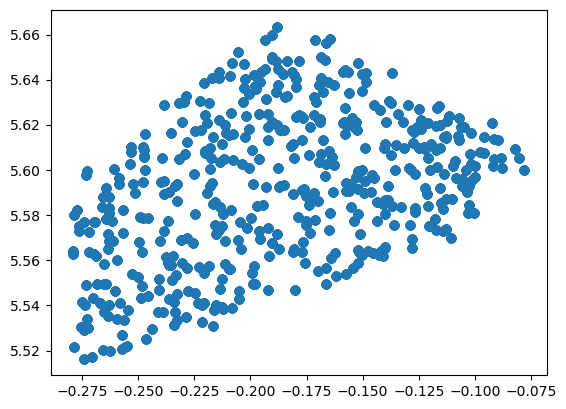

In [51]:
master_gdf_final.plot()

In [52]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

In [54]:
df = pd.read_csv("Accra_Master_Spatiotemporal_Panel.csv")

In [55]:
# Create spatial group for spatial cross-validation
if 'id' in df.columns:
    df['spatial_group'] = df['id']
else:
    df['spatial_group'] = df['latitude'].round(4).astype(str) + "_" + df['longitude'].round(4).astype(str)

In [56]:
# Extract date features
df['date'] = pd.to_datetime(df['date'])
df['day_of_year'] = df['date'].dt.dayofyear
df['month'] = df['date'].dt.month

In [57]:
# Aspect Transformation (Aspect has NaNs, numpy handles them safely)
df['aspect_sin'] = np.sin(np.radians(df['aspect']))
df['aspect_cos'] = np.cos(np.radians(df['aspect']))

In [58]:
# Define feature list (Includes features with NaNs like NO2, NDVI, aspect, pop_density)
feature_cols = [
    'latitude', 'longitude', 'day_of_year', 'month',
    'u10', 'v10', 'wind_speed', 'wind_dir_deg',
    'PBLH_mean', 'PBLH_min', 'PBLH_max',
    'NO2', 'NDVI',
    'elevation', 'slope', 'aspect_sin', 'aspect_cos',
    'pop_density'
]

In [59]:
# Train/Val Set: Rows where AOD is present
train_val_df = df[df['AOD'].notnull()].copy().reset_index(drop=True)

In [60]:
# Prediction Set: Rows where AOD is NaN (14,837 rows to impute)
predict_df = df[df['AOD'].isnull()].copy().reset_index(drop=True)

In [61]:
print(f"📊 Known AOD rows (Used for Training & CV): {len(train_val_df):,}")
print(f"🔮 Missing AOD rows (Target to Impute):     {len(predict_df):,}")

📊 Known AOD rows (Used for Training & CV): 5,743
🔮 Missing AOD rows (Target to Impute):     14,837


In [62]:
# 3. SPATIAL CROSS-VALIDATION (GroupKFold)
# =====================================================================
X_train_val = train_val_df[feature_cols]
y_train_val = train_val_df['AOD']
groups = train_val_df['spatial_group']

In [63]:
gkf = GroupKFold(n_splits=5)

In [64]:
oof_predictions = np.zeros(len(train_val_df))
models = []

print("\n🚀 Starting 5-Fold Spatial Cross-Validation...")
print("-" * 55)


🚀 Starting 5-Fold Spatial Cross-Validation...
-------------------------------------------------------


In [65]:
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_train_val, y_train_val, groups=groups), start=1):
    X_tr, y_tr = X_train_val.iloc[train_idx], y_train_val.iloc[train_idx]
    X_va, y_va = X_train_val.iloc[val_idx], y_train_val.iloc[val_idx]
    
    # XGBoost handles NaNs in feature_cols automatically via 'missing=np.nan'
    model = xgb.XGBRegressor(
        n_estimators=800,
        learning_rate=0.03,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method='hist',
        missing=np.nan,  # Explicitly tell XGBoost to learn optimal split directions for missing feature values
        random_state=42,
        n_jobs=-1
    )
    
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )
    
    val_preds = model.predict(X_va)
    oof_predictions[val_idx] = val_preds
    models.append(model)
    
    fold_rmse = np.sqrt(mean_squared_error(y_va, val_preds))
    fold_r2   = r2_score(y_va, val_preds)
    print(f"Fold {fold} | RMSE: {fold_rmse:.4f} | R²: {fold_r2:.4f}")

Fold 1 | RMSE: 0.0255 | R²: 0.9877
Fold 2 | RMSE: 0.0237 | R²: 0.9896
Fold 3 | RMSE: 0.0220 | R²: 0.9908
Fold 4 | RMSE: 0.0211 | R²: 0.9916
Fold 5 | RMSE: 0.0206 | R²: 0.9919


In [66]:
# Cross-Validation Summary
total_rmse = np.sqrt(mean_squared_error(y_train_val, oof_predictions))
total_mae  = mean_absolute_error(y_train_val, oof_predictions)
total_r2   = r2_score(y_train_val, oof_predictions)

print("-" * 55)
print(f"🏆 OVERALL SPATIAL CV PERFORMANCE:")
print(f" • RMSE: {total_rmse:.4f}")
print(f" • MAE:  {total_mae:.4f}")
print(f" • R²:   {total_r2:.4f}")

-------------------------------------------------------
🏆 OVERALL SPATIAL CV PERFORMANCE:
 • RMSE: 0.0226
 • MAE:  0.0131
 • R²:   0.9903


In [68]:
# Safely extract best_iteration (defaults to 800 if early stopping was not triggered)
best_trees = [m.best_iteration for m in models if hasattr(m, 'best_iteration') and m.best_iteration is not None]
n_trees_final = int(np.mean(best_trees)) if len(best_trees) > 0 else 800

final_model = xgb.XGBRegressor(
    n_estimators=n_trees_final,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    missing=np.nan,
    random_state=42,
    n_jobs=-1
)
final_model.fit(X_train_val, y_train_val)

# Predict missing AODs
print(f"🔮 Imputing {len(predict_df):,} missing AOD values...")
imputed_preds = final_model.predict(predict_df[feature_cols])

🔮 Imputing 14,837 missing AOD values...


In [69]:
# Assign predictions and flags
predict_df['AOD_Final'] = np.clip(imputed_preds, 0, None)  # Ensure non-negative AOD
predict_df['is_imputed'] = True

train_val_df['AOD_Final'] = train_val_df['AOD']
train_val_df['is_imputed'] = False

# Recombine into full master dataset
final_df = pd.concat([train_val_df, predict_df], ignore_index=True)
final_df = final_df.sort_values(['latitude', 'longitude', 'date']).reset_index(drop=True)

In [70]:
final_df.head()

,date,latitude,longitude,u10,v10,wind_speed,wind_dir_deg,AOD,NO2,NDVI,...,elevation,slope,pop_density,spatial_group,day_of_year,month,aspect_sin,aspect_cos,AOD_Final,is_imputed
0,2026-01-01,5.5164,-0.274,2.895965,2.239334,3.660770,232.286650,NaN,NaN,NaN,...,1.0,NaN,NaN,5.5164_-0.274,1,1,NaN,NaN,0.131678,True
1,2026-01-02,5.5164,-0.274,2.725430,2.579871,3.752826,226.571606,NaN,0.000060,NaN,...,1.0,NaN,NaN,5.5164_-0.274,2,1,NaN,NaN,0.198181,True
2,2026-01-03,5.5164,-0.274,1.672285,2.169571,2.739265,217.624696,NaN,0.000048,NaN,...,1.0,NaN,NaN,5.5164_-0.274,3,1,NaN,NaN,0.096850,True
3,2026-01-04,5.5164,-0.274,1.191090,2.009478,2.335957,210.656747,0.422,0.000046,NaN,...,1.0,NaN,NaN,5.5164_-0.274,4,1,NaN,NaN,0.422000,False
4,2026-01-05,5.5164,-0.274,2.044441,1.852202,2.758694,227.824381,0.315,0.000066,NaN,...,1.0,NaN,NaN,5.5164_-0.274,5,1,NaN,NaN,0.315000,False


<Axes: >

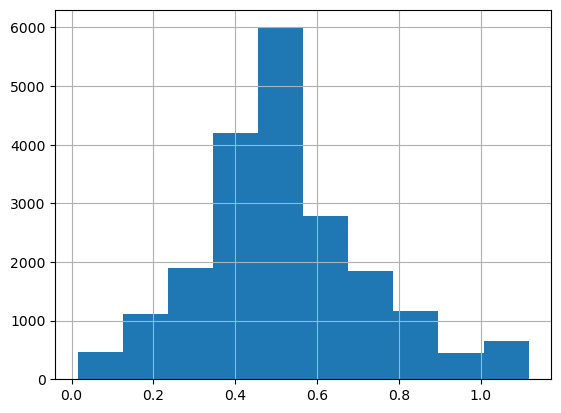

In [71]:
final_df['AOD_Final'].hist()